# Periodically forced Duffing oscillator

A double-well oscillator (`a = -1`, `b = 1`) with damping `d` and periodic forcing
`f cos(om t)`. The equations depend on time, so there is no fixed direction field; the
Poincaré section (strobing once per forcing period) shows the attractor.

*Based on an example from XPP Studio (Peter Ashwin and Bard Ermentrout, GPL-3.0). Every number below is computed by XPPAUT 8.1 and its AUTO through pyauto-xpp.*

In [1]:
import plotly.graph_objects as go
from pyxpp.builder import ModelBuilder
from xpptut import Explorer, load, orbit_diagram, show_figure

## The model

Written with `ModelBuilder`, statement by statement as in an `.ode` file. Edit it and rerun the cells below.

In [2]:
mb = (ModelBuilder("forced_duffing")
      .ode("x", "y")
      .ode("y", "-d*y-a*x-b*x^3+f*cos(om*t)")
      .parameter(d=0.15, a=-1, b=1, f=0.3, om=1.2)
      .initial(x=1, y=0)
      .option(total=200, dt=0.02, meth="rk4"))
print(mb.render())

x'=y
y'=-d*y-a*x-b*x^3+f*cos(om*t)
par d=0.15,a=-1,b=1,f=0.3,om=1.2
init x=1,y=0
@ total=200,dt=0.02,meth=rk4
done



## Explore

The sliders, the direction-field menu and the AUTO panel all call XPP. `ex.m` is the pyxpp model, for anything else.

In [3]:
ex = Explorer(mb, kind="plane", x="x", y="y", window=(-2, 2, -1.5, 1.5), df=False, nullclines=False,
              sliders={"f": (0, 0.6), "d": (0, 0.6)}, title="Forced Duffing")
ex

Explorer(children=(HTML(value="<h3 style='margin:4px 0'>Forced Duffing</h3>"), HBox(children=(VBox(children=(F…

## Going further

**Stroboscopic (Poincaré) map**: sample once every forcing period 2π/om.

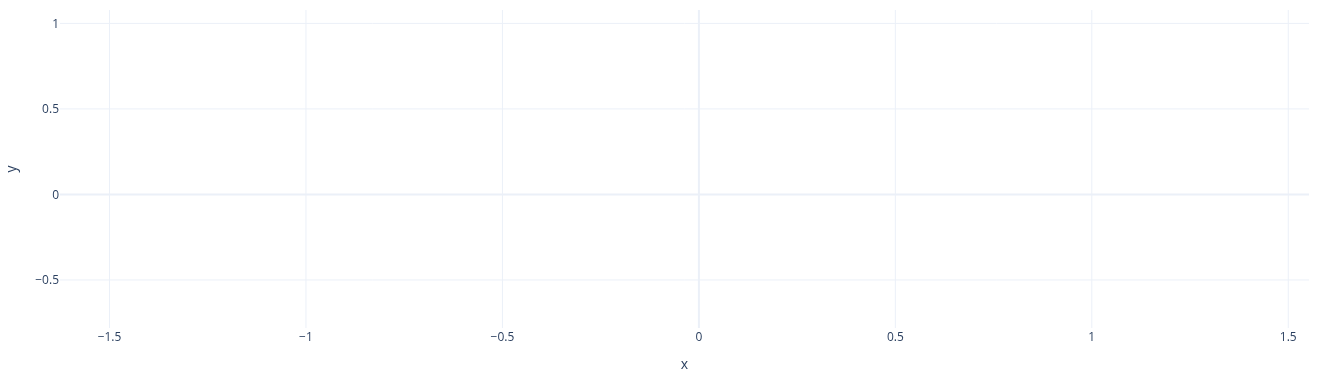

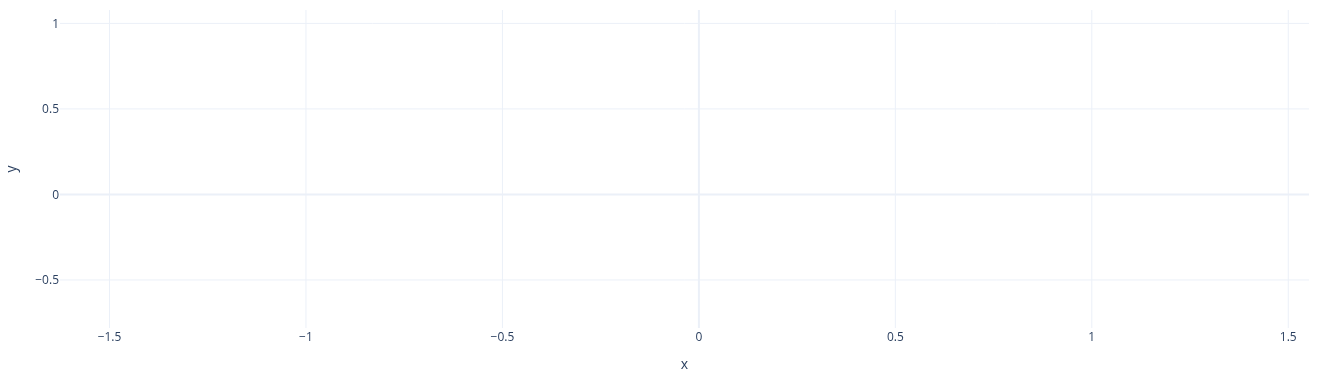

In [5]:
import numpy as np
om = ex.m.pars["om"]
T = 2 * np.pi / om
tr = ex.m.run(keep=False, total=3000 * T, dt=T / 200, nout=200, trans=50 * T)
show_figure(go.Figure(go.Scattergl(x=tr["x"], y=tr["y"], mode="markers", marker=dict(size=2))),
            xaxis_title="x", yaxis_title="y", height=380)

## Things to try

- Slide `f` from 0.2 to 0.4: periodic motion, period doubling, chaos.